In [1]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

record = wfdb.rdrecord('100', pn_dir='mitdb')
fs = record.fs
ecg = record.p_signal[:, 0]
t = np.arange(len(ecg)) / fs

# Same filters as notebook 02
b_notch, a_notch = signal.iirnotch(60.0, 30.0, fs=fs)
sos_bp = signal.butter(4, [0.5, 40], btype='bandpass', fs=fs, output='sos')
ecg_filt = signal.sosfiltfilt(sos_bp, signal.filtfilt(b_notch, a_notch, ecg))

print("Ready:", len(ecg_filt), "filtered samples")

Ready: 650000 filtered samples


In [2]:
# Rules for an R-peak:
#  - taller than a threshold (half of the signal's 99th percentile)
#  - at least 0.25 s after the previous peak (heart can't beat faster than ~240 bpm)
height_threshold = 0.5 * np.percentile(ecg_filt, 99)
min_distance = int(0.25 * fs)

r_peaks, _ = signal.find_peaks(ecg_filt, height=height_threshold, distance=min_distance)

duration_min = len(ecg_filt) / fs / 60
print(f"Height threshold: {height_threshold:.2f} mV")
print(f"Beats detected:   {len(r_peaks)}")
print(f"Recording length: {duration_min:.1f} min")
print(f"Average heart rate: {len(r_peaks) / duration_min:.1f} bpm")

Height threshold: 0.54 mV
Beats detected:   2273
Recording length: 30.1 min
Average heart rate: 75.5 bpm


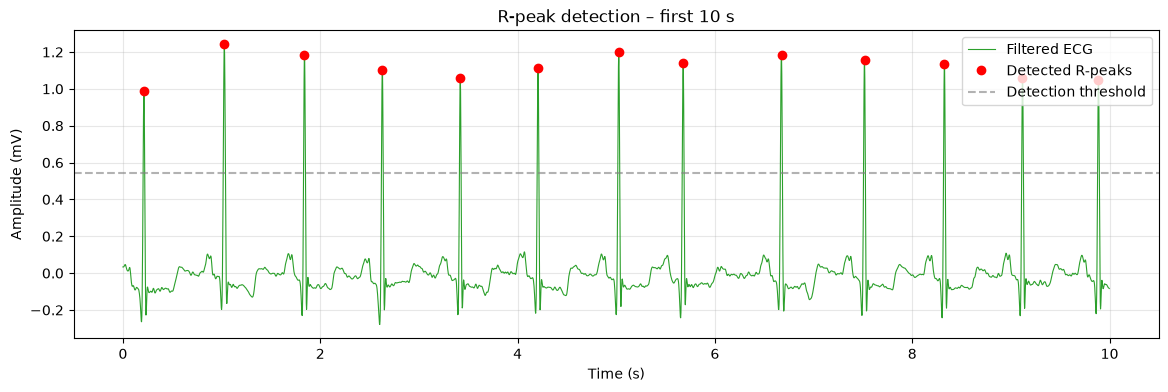

In [3]:
n = 10 * fs
mask = r_peaks < n

plt.figure(figsize=(14, 4))
plt.plot(t[:n], ecg_filt[:n], linewidth=0.8, color='tab:green', label='Filtered ECG')
plt.plot(t[r_peaks[mask]], ecg_filt[r_peaks[mask]], 'ro', markersize=6, label='Detected R-peaks')
plt.axhline(height_threshold, color='gray', linestyle='--', alpha=0.6, label='Detection threshold')
plt.title("R-peak detection – first 10 s")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.savefig('figures/07_rpeak_detection.png', dpi=150, bbox_inches='tight')
plt.show()

Mean HR: 75.8 bpm   (min 58.4, max 114.9)
Mean RR interval: 795 ms
SDNN:  48.0 ms
RMSSD: 61.4 ms


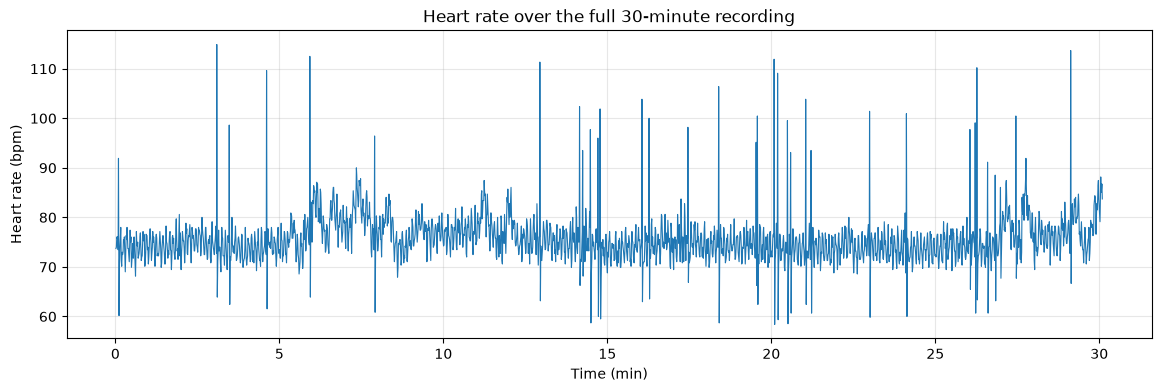

In [4]:
rr = np.diff(r_peaks) / fs           # RR intervals: seconds between beats
hr = 60 / rr                          # instantaneous heart rate (bpm)

sdnn = np.std(rr) * 1000                          # ms
rmssd = np.sqrt(np.mean(np.diff(rr) ** 2)) * 1000 # ms

print(f"Mean HR: {hr.mean():.1f} bpm   (min {hr.min():.1f}, max {hr.max():.1f})")
print(f"Mean RR interval: {rr.mean()*1000:.0f} ms")
print(f"SDNN:  {sdnn:.1f} ms")
print(f"RMSSD: {rmssd:.1f} ms")

plt.figure(figsize=(14, 4))
plt.plot(t[r_peaks[1:]] / 60, hr, linewidth=0.8)
plt.title("Heart rate over the full 30-minute recording")
plt.xlabel("Time (min)")
plt.ylabel("Heart rate (bpm)")
plt.grid(True, alpha=0.3)
plt.savefig('figures/08_heart_rate_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# Load expert annotations and keep only real heartbeat labels
ann = wfdb.rdann('100', 'atr', pn_dir='mitdb')
beat_codes = set('NLRBAaJSVrFejnE/fQ')
ref = np.array([s for s, sym in zip(ann.sample, ann.symbol) if sym in beat_codes])
ref_sym = np.array([sym for sym in ann.symbol if sym in beat_codes])

# A detection counts as correct if it is within 150 ms of an expert beat
# (the tolerance used in the ANSI/AAMI EC57 standard for beat detectors)
tol = int(0.150 * fs)

used = np.zeros(len(r_peaks), dtype=bool)
det_label = np.array(['?'] * len(r_peaks))   # which expert label each detection matched
tp, offsets = 0, []

for s, sym in zip(ref, ref_sym):
    i = np.searchsorted(r_peaks, s)
    best = None
    for j in (i - 1, i):
        if 0 <= j < len(r_peaks) and not used[j] and abs(r_peaks[j] - s) <= tol:
            if best is None or abs(r_peaks[j] - s) < abs(r_peaks[best] - s):
                best = j
    if best is not None:
        used[best] = True
        det_label[best] = sym
        tp += 1
        offsets.append((r_peaks[best] - s) / fs * 1000)

fn = len(ref) - tp          # expert beats we missed
fp = len(r_peaks) - tp      # detections that weren't real beats

sensitivity = tp / (tp + fn) * 100
ppv = tp / (tp + fp) * 100

print(f"Expert beats:          {len(ref)}")
print(f"Detected beats:        {len(r_peaks)}")
print(f"True positives (TP):   {tp}")
print(f"Missed beats (FN):     {fn}")
print(f"False detections (FP): {fp}")
print(f"Sensitivity:           {sensitivity:.2f} %")
print(f"Positive predictivity: {ppv:.2f} %")
print(f"Timing offset vs expert: mean {np.mean(offsets):.1f} ms, std {np.std(offsets):.1f} ms")
print("Beat types matched:", {k: int((det_label == k).sum()) for k in sorted(set(det_label))})

Expert beats:          2273
Detected beats:        2273
True positives (TP):   2272
Missed beats (FN):     1
False detections (FP): 1
Sensitivity:           99.96 %
Positive predictivity: 99.96 %
Timing offset vs expert: mean 0.2 ms, std 1.0 ms
Beat types matched: {np.str_('?'): 1, np.str_('A'): 33, np.str_('N'): 2239}


In [6]:
# Keep only RR intervals where BOTH beats are normal ('N')
rr_all = np.diff(r_peaks) / fs
nn_mask = (det_label[:-1] == 'N') & (det_label[1:] == 'N')
nn = rr_all[nn_mask]

sdnn_nn = np.std(nn) * 1000
rmssd_nn = np.sqrt(np.mean(np.diff(nn) ** 2)) * 1000

print(f"NN intervals used: {len(nn)} of {len(rr_all)}")
print(f"Mean HR (NN):      {60 / nn.mean():.1f} bpm")
print(f"SDNN  – all beats: {sdnn:.1f} ms  |  normal beats only: {sdnn_nn:.1f} ms")
print(f"RMSSD – all beats: {rmssd:.1f} ms  |  normal beats only: {rmssd_nn:.1f} ms")

NN intervals used: 2204 of 2272
Mean HR (NN):      75.5 bpm
SDNN  – all beats: 48.0 ms  |  normal beats only: 36.0 ms
RMSSD – all beats: 61.4 ms  |  normal beats only: 27.9 ms


MISSED: expert beat 'V' at 1518.87 s
FALSE DETECTION at 1519.13 s


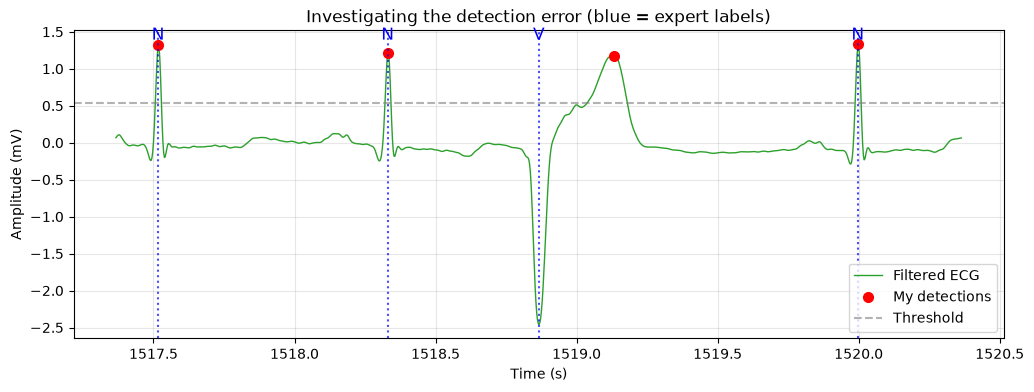

In [7]:
# Expert beats with no detection within 150 ms
missed = [(s, sym) for s, sym in zip(ref, ref_sym)
          if np.min(np.abs(r_peaks[used] - s)) > tol]
# Detections that didn't match any expert beat
false_pos = r_peaks[~used]

for s, sym in missed:
    print(f"MISSED: expert beat '{sym}' at {s/fs:.2f} s")
for p in false_pos:
    print(f"FALSE DETECTION at {p/fs:.2f} s")

# Plot 3 seconds around the missed beat
s0 = missed[0][0]
a, b = s0 - int(1.5 * fs), s0 + int(1.5 * fs)
win_peaks = r_peaks[(r_peaks >= a) & (r_peaks < b)]
win_ref = [(s, sym) for s, sym in zip(ref, ref_sym) if a <= s < b]

plt.figure(figsize=(12, 4))
plt.plot(t[a:b], ecg_filt[a:b], color='tab:green', linewidth=1, label='Filtered ECG')
plt.plot(t[win_peaks], ecg_filt[win_peaks], 'ro', markersize=7, label='My detections')
for s, sym in win_ref:
    plt.axvline(t[s], color='blue', linestyle=':', alpha=0.7)
    plt.text(t[s], ecg_filt[a:b].max() * 1.05, sym, color='blue', ha='center', fontsize=12)
plt.axhline(height_threshold, color='gray', linestyle='--', alpha=0.6, label='Threshold')
plt.title("Investigating the detection error (blue = expert labels)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (mV)")
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.savefig('figures/09_detection_error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
def evaluate(peaks, tol=int(0.150 * fs)):
    """Match detected peaks to expert beats; return TP, FN, FP and matched labels."""
    used = np.zeros(len(peaks), dtype=bool)
    labels = np.array(['?'] * len(peaks))
    for s, sym in zip(ref, ref_sym):
        i = np.searchsorted(peaks, s)
        best = None
        for j in (i - 1, i):
            if 0 <= j < len(peaks) and not used[j] and abs(peaks[j] - s) <= tol:
                if best is None or abs(peaks[j] - s) < abs(peaks[best] - s):
                    best = j
        if best is not None:
            used[best] = True
            labels[best] = sym
    tp = int(used.sum())
    return tp, len(ref) - tp, len(peaks) - tp, labels

# Version 2: detect on |signal| so downward beats count too
abs_ecg = np.abs(ecg_filt)
thr_v2 = 0.5 * np.percentile(abs_ecg, 99)
r_peaks_v2, _ = signal.find_peaks(abs_ecg, height=thr_v2, distance=int(0.30 * fs))

for name, pk in [("v1 (upward peaks only)", r_peaks), ("v2 (absolute value)", r_peaks_v2)]:
    tp_, fn_, fp_, lab = evaluate(pk)
    print(f"{name:24s} TP={tp_}  FN={fn_}  FP={fp_}  "
          f"Sensitivity={tp_/(tp_+fn_)*100:.2f}%  PPV={tp_/(tp_+fp_)*100:.2f}%  "
          f"V matched={int((lab=='V').sum())}")

v1 (upward peaks only)   TP=2272  FN=1  FP=1  Sensitivity=99.96%  PPV=99.96%  V matched=0
v2 (absolute value)      TP=2273  FN=0  FP=0  Sensitivity=100.00%  PPV=100.00%  V matched=1
